# Late Delivery Prediction

## Project Overview

This project uses Machine Learning to predict which e-commerce orders are likely to arrive later than the promised delivery date. The project uses the Olist Brazilian E-Commerce Dataset, with data extracted from PostgreSQL after going through a Data Pipeline.

### Business Problem

In an e-commerce business, thousands of orders are delivered to customers. While most orders arrive on time, some are delivered late. Late deliveries can affect customer satisfaction and create more work for the operations team. However, checking every order takes a lot of time and effort. The main question is can we use Machine Learning to identify orders that are likely to be delivered late, so the operations team can focus on the most risky orders first?

###  Project Goal

The goal is to build a Machine Learning model that predicts the risk of late delivery. The prediction is made when the seller hands the package to the shipping carrier, before the customer receives it.
At this point, we already know useful information, such as:
- How many days the seller took to prepare the order.
- How many days are left before the promised delivery date.
- Order details, shipping costs, and customer location.
- Historical shipping information available at prediction time.
The model uses this information to give each order a risk score. A higher score means the order is more likely to be delivered late.

## Environment

```powershell
conda activate olist-ml
python -m pip install -r requirements.txt
python -m ipykernel install --user --name olist-ml --display-name "Python (olist-ml)"
python -m jupyter lab
```

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import json
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)
from catboost import CatBoostClassifier

RANDOM_STATE = 42
REVIEW_CAPACITY = 0.15 
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format) 

def locate_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "requirements.txt").exists() and (folder / "notebooks").exists():
            return folder
    raise FileNotFoundError("Open Jupyter from the project directory containing requirements.txt.")

PROJECT_ROOT = locate_root()
load_dotenv(PROJECT_ROOT / ".env")

True

## Connect to PostgreSQL

In [4]:

def env_value(primary, fallback=None, default=None):
    return os.getenv(primary) or (os.getenv(fallback) if fallback else None) or default

credentials = {
    "username": env_value("ML_DB_USER", "WAREHOUSE_USER"),
    "password": env_value("ML_DB_PASSWORD", "WAREHOUSE_PASSWORD"),
    "database": env_value("ML_DB_NAME", "WAREHOUSE_DB"),
}
missing = [key for key, val in credentials.items() if not val]
if missing:
    raise EnvironmentError(f"Missing credentials: {missing}. Edit your local .env file.")


url = URL.create(
    "postgresql+psycopg2", username=credentials["username"],
    password=credentials["password"], database=credentials["database"],
    host=env_value("ML_DB_HOST", default="localhost"),
    port=int(env_value("ML_DB_PORT", "WAREHOUSE_PORT", "5432")),
)




# ("schema", "table")
engine = create_engine(url, pool_pre_ping=True, connect_args={"connect_timeout": 10})
needed = {
    ("analytics_core", "fct_orders"), ("analytics_core", "fct_order_items"),
    ("analytics_core", "dim_products"), ("analytics_core", "dim_sellers"),
    ("analytics_core", "dim_geography"), ("analytics_core", "fct_payments"),
    ("analytics_staging", "stg_orders"), ("analytics_staging", "stg_customers"),
}
with engine.connect() as conn:
    
    found = set(conn.execute(text("""
        SELECT table_schema, table_name FROM information_schema.tables
        WHERE table_schema IN ('analytics_core', 'analytics_staging')
    """)).all())
    
    db_name = conn.execute(text("SELECT current_database() ")).scalar_one()
if needed - found:
    raise RuntimeError("Missing dbt models: " + str(sorted(needed - found)))
print(f"Connected to {db_name}; {len(needed)} required models are available.")

Connected to olist_ecommerce; 8 required models are available.


## SQL Data Extraction

Extract data from PostgreSQL and prepare **one row per order** for Machine Learning.

- **Avoid duplicate orders:** If an order has 2 items and 2 payments, joining the tables directly creates 4 rows. We aggregate the data first to keep only 1 row per order.
- **Select the main seller:** If an order has multiple sellers, Choose the seller with the highest-priced item.
- **Add useful features:** Use product details and customer/seller locations to create features such as product weight and estimated shipping distance.
- **Create the target:** Use the actual delivery date to check whether an order arrived late. This information is not used as a prediction feature.
- **Prevent Data Leakage:** Only use information available when the seller hands the package to the carrier. Historical features must also use information available before that time.

**Example:**

A customer places an order on June 1, and the seller hands it to the carrier on June 7. The promised delivery date is June 10. At carrier handoff, the model knows the seller took 6 days to prepare the order and that only 3 days remain before the deadline. The model uses this information to predict whether the order might arrive late, without knowing the actual delivery date.

In [5]:
QUERY = """
WITH item_agg AS (
  SELECT
    i.order_id,
    COUNT(DISTINCT i.seller_key) AS distinct_sellers,
    COUNT(DISTINCT p.category_english) AS distinct_categories,
    AVG(NULLIF(p.product_weight_g, 0))::double precision AS avg_product_weight_g,
    MAX(NULLIF(p.product_weight_g, 0))::double precision AS max_product_weight_g,
    AVG(CASE WHEN p.product_length_cm > 0 AND p.product_height_cm > 0
                 AND p.product_width_cm > 0
             THEN (p.product_length_cm::numeric * p.product_height_cm * p.product_width_cm)
        END)::double precision AS avg_product_volume_cm3,
    MODE() WITHIN GROUP (ORDER BY COALESCE(p.category_english, 'unknown')) AS main_category,
    MIN(i.shipping_limit_date) AS first_ship_deadline_at,
    MAX(i.shipping_limit_date) AS last_ship_deadline_at
  FROM analytics_core.fct_order_items i
  LEFT JOIN analytics_core.dim_products p ON i.product_key = p.product_key
  GROUP BY i.order_id
),
primary_seller AS (
  SELECT order_id, seller_key
  FROM (
    SELECT i.order_id, i.seller_key,
           ROW_NUMBER() OVER (
             PARTITION BY i.order_id
             ORDER BY i.item_price DESC NULLS LAST, i.seller_key
           ) AS rn
    FROM analytics_core.fct_order_items i
  ) s
  WHERE rn = 1
),
payment_agg AS (
  SELECT order_id,
         SUM(payment_value)::double precision AS payment_total,
         MAX(payment_installments) AS max_installments,
         MODE() WITHIN GROUP (ORDER BY COALESCE(payment_type, 'unknown')) AS main_payment_type
  FROM analytics_core.fct_payments
  GROUP BY order_id
)
SELECT
  o.order_id,
  o.purchased_at,
  src.order_approved_at AS approved_at,
  src.order_delivered_carrier_date AS carrier_at,
  o.delivered_at,
  o.estimated_delivery_at,
  (NOT o.is_on_time)::integer AS late_delivery,
  o.order_gmv::double precision AS order_gmv,
  o.freight_total::double precision AS freight_total,
  o.item_count,
  c.customer_state,
  c.customer_zip_code_prefix,
  ps.seller_key AS main_seller_id,
  s.seller_state AS main_seller_state,
  s.seller_zip_code_prefix,
  i.distinct_sellers,
  i.distinct_categories,
  i.avg_product_weight_g,
  i.max_product_weight_g,
  i.avg_product_volume_cm3,
  i.main_category,
  i.first_ship_deadline_at,
  i.last_ship_deadline_at,
  cg.latitude AS customer_lat,
  cg.longitude AS customer_lng,
  sg.latitude AS seller_lat,
  sg.longitude AS seller_lng,
  pay.payment_total,
  pay.max_installments,
  pay.main_payment_type
FROM analytics_core.fct_orders o
JOIN analytics_staging.stg_orders src ON o.order_id = src.order_id
JOIN analytics_staging.stg_customers c ON src.customer_id = c.customer_id
JOIN item_agg i ON o.order_id = i.order_id
LEFT JOIN primary_seller ps ON o.order_id = ps.order_id
LEFT JOIN analytics_core.dim_sellers s ON ps.seller_key = s.seller_key
LEFT JOIN analytics_core.dim_geography cg ON c.customer_zip_code_prefix = cg.zip_code_prefix
LEFT JOIN analytics_core.dim_geography sg ON s.seller_zip_code_prefix = sg.zip_code_prefix
LEFT JOIN payment_agg pay ON o.order_id = pay.order_id
WHERE o.order_status = 'delivered'
  AND o.is_on_time IS NOT NULL
  AND o.purchased_at IS NOT NULL
  AND o.estimated_delivery_at IS NOT NULL
  AND o.delivered_at IS NOT NULL
  AND src.order_delivered_carrier_date IS NOT NULL
  AND o.item_count > 0
ORDER BY src.order_delivered_carrier_date, o.order_id
"""
with engine.connect() as conn:
    orders = pd.read_sql_query(text(QUERY), conn)
if orders.empty:
    raise ValueError("No eligible orders returned. Check the pipeline and the SQL filters.")
print(f"Extracted {len(orders):,} carrier-handoff orders, {orders.shape[1]} columns")
display(orders.head(10))

Extracted 96,469 carrier-handoff orders, 30 columns


,order_id,purchased_at,approved_at,carrier_at,delivered_at,estimated_delivery_at,late_delivery,order_gmv,freight_total,item_count,customer_state,customer_zip_code_prefix,main_seller_id,main_seller_state,seller_zip_code_prefix,distinct_sellers,distinct_categories,avg_product_weight_g,max_product_weight_g,avg_product_volume_cm3,main_category,first_ship_deadline_at,last_ship_deadline_at,customer_lat,customer_lng,seller_lat,seller_lng,payment_total,max_installments,main_payment_type
0,cd3b8574c82b42fc8129f6d502690c3e,2016-10-03 22:31:31,2016-10-04 10:19:23,2016-10-08 10:34:01,2016-10-14 16:08:00,2016-11-23,0,29.990,10.960,1,SP,12030,b499c00f28f4b7069ff6550af8c1348a,SP,13481,1,1,"9,000.000","9,000.000","2,640.000",fashion_shoes,2016-10-08 10:34:01,2016-10-08 10:34:01,-23.033,-45.569,-22.600,-47.409,40.950,4.000,credit_card
1,36989eb07a0de2d3d3129eea35553875,2016-10-04 13:11:29,2016-10-04 13:46:31,2016-10-08 13:46:32,2016-10-11 13:46:32,2016-12-06,0,47.800,53.640,2,MT,78075,939f6e231201f26803cb5c3a3d2940b3,SP,17051,1,1,"1,500.000","1,500.000","14,625.000",furniture_decor,2016-10-08 13:46:32,2016-10-08 13:46:32,-15.610,-56.032,-22.331,-49.101,101.440,10.000,credit_card
2,7033745709b7cf1bac7d2533663592de,2016-10-04 14:13:22,2016-10-04 14:46:48,2016-10-08 14:46:49,2016-10-11 14:46:49,2016-11-30,0,93.900,17.610,1,RJ,21853,df560393f3a51e74553ab94004ba5c87,PR,87900,1,1,"1,200.000","1,200.000","12,500.000",furniture_decor,2016-10-08 14:46:49,2016-10-08 14:46:49,-22.852,-43.490,-22.931,-53.136,111.510,4.000,credit_card
3,fbbc9a4fa88f1ccd651790df665b3e57,2016-10-04 13:30:13,2016-10-05 02:45:16,2016-10-09 02:45:17,2016-10-28 17:05:47,2016-12-02,0,99.900,19.530,1,ES,29300,ecccfa2bb93b34a3bf033cc5d1dcdc69,PR,81810,1,1,"1,400.000","1,400.000","8,000.000",health_beauty,2016-10-09 02:45:17,2016-10-09 02:45:17,-20.848,-41.119,-25.507,-49.277,119.430,1.000,boleto
4,bcbc0973414b1dd97555e6f8e9713cfa,2016-10-04 23:59:01,2016-10-05 03:45:41,2016-10-09 03:45:42,2016-10-16 10:41:50,2016-11-28,0,319.600,63.640,4,PR,87820,cca3071e3e9bb7d12640c9fbe2301306,SP,14940,1,2,"1,250.000","1,400.000","6,072.000",bed_bath_table,2016-10-09 03:45:42,2016-10-09 03:45:42,-23.383,-52.941,-21.758,-48.829,383.240,3.000,credit_card
5,51725d3e4bdfc97e28b40543310da8a3,2016-10-04 15:02:53,2016-10-05 17:06:51,2016-10-09 17:06:52,2016-10-26 13:21:41,2016-11-28,0,119.800,29.740,2,SC,89124,ecccfa2bb93b34a3bf033cc5d1dcdc69,PR,81810,1,1,"1,150.000","1,300.000","8,000.000",health_beauty,2016-10-09 17:06:52,2016-10-09 17:06:52,-26.783,-49.363,-25.507,-49.277,149.540,7.000,credit_card
6,cbbb524a0e1646aa6cf7a3c0bbe517ad,2016-10-05 07:31:49,2016-10-06 02:46:24,2016-10-10 02:46:24,2016-10-16 14:36:00,2016-12-07,0,75.000,20.580,1,PE,50090,229c3efbfb0ea2058de4ccdfbc3d784a,MG,30190,1,1,250.000,250.000,"4,200.000",computers_accessories,2016-10-10 02:46:24,2016-10-10 02:46:24,-8.074,-34.894,-19.923,-43.948,95.580,1.000,boleto
7,98750f114ae6088d04ea0d3cfe3f137f,2016-10-05 11:44:41,2016-10-06 03:07:51,2016-10-10 03:07:51,2016-10-28 12:23:43,2016-11-29,0,10.000,14.520,1,RJ,20760,63b9ae557efed31d1f7687917d248a8d,SP,13720,1,1,100.000,100.000,"4,500.000",auto,2016-10-10 03:07:51,2016-10-10 03:07:51,-22.878,-43.287,-21.601,-46.894,24.520,1.000,boleto
8,d1eb8e4e276a4eea13a5c462c0765e60,2016-10-04 19:30:28,2016-10-06 03:10:33,2016-10-10 03:10:34,2016-10-13 03:10:34,2016-12-06,0,19.990,20.800,1,BA,45820,2138ccb85b11a4ec1e37afbd1c8eda1f,SP,08250,1,1,175.000,175.000,648.000,telephony,2016-10-10 03:10:34,2016-10-10 03:10:34,-16.375,-39.587,-23.540,-46.436,40.790,1.000,boleto
9,92b44b87f1f7670b8911c5f0e642435e,2016-10-05 11:08:46,2016-10-06 07:45:47,2016-10-10 07:45:48,2016-10-13 07:45:48,2016-11-25,0,149.990,11.660,1,SP,13630,62c50c1af4dfdc4149d25c5222043d39,SP,04782,1,1,900.000,900.000,"8,000.000",fixed_telephony,2016-10-10 07:45:48,2016-10-10 07:45:48,-21.994,-47.428,-23.691,-46.704,161.650,1.000,boleto


## Data Quality Checks

- **Check missing values:** Identify columns with missing data and review whether they can be used.
- **Filter valid orders:** Keep only delivered orders with a recorded carrier handoff date.
- **Check delivery timelines:** Remove orders with impossible dates, such as a delivery date earlier than the carrier handoff date.
- **Validate the target:** Make sure the `late_delivery` label follows the same rule used in the original dbt pipeline.

Orders without a recorded carrier handoff date are excluded. This means the dataset may not represent all orders, which could affect how well the model performs on different types of shipments.

In [6]:
DATE_COLS = ["purchased_at", "approved_at", "carrier_at", "delivered_at",
             "estimated_delivery_at", "first_ship_deadline_at", "last_ship_deadline_at"]



for col in DATE_COLS:
    orders[col] = pd.to_datetime(orders[col], errors="coerce") 
assert orders["order_id"].is_unique, "SQL joins produced multiple rows per order"
assert orders["late_delivery"].notna().all()
assert orders["late_delivery"].isin([0, 1]).all()

bad_timeline = (
    orders["carrier_at"].isna() | orders["delivered_at"].isna() |
    (orders["carrier_at"] < orders["purchased_at"]) |
    (orders["delivered_at"] < orders["carrier_at"]) |
    (orders["estimated_delivery_at"] < orders["purchased_at"])
)
print("Invalid timeline rows excluded:", int(bad_timeline.sum()))
orders = orders.loc[~bad_timeline].copy() 
if len(orders) < 1000:
    raise ValueError("Too few valid observations for a useful temporal evaluation")

expected_label = (
    orders["delivered_at"].dt.normalize() > orders["estimated_delivery_at"].dt.normalize()
).astype(int)
# .dt.normalize()

assert expected_label.eq(orders["late_delivery"]).all(), "Target mismatch with dbt fct_orders"
print("Valid orders:", len(orders))
print("Late-delivery rate:", f"{orders['late_delivery'].mean():.2%}")
print("Carrier dates:", orders["carrier_at"].min().date(), "to", orders["carrier_at"].max().date())
display(orders.isna().mean().sort_values(ascending=False).head(12).to_frame("missing_fraction")) 



Invalid timeline rows excluded: 188
Valid orders: 96281
Late-delivery rate: 6.78%
Carrier dates: 2016-10-08 to 2018-09-11


,missing_fraction
customer_lat,0.003
customer_lng,0.003
seller_lat,0.002
seller_lng,0.002
max_product_weight_g,0.000
avg_product_weight_g,0.000
avg_product_volume_cm3,0.000
approved_at,0.000
max_installments,0.000
main_payment_type,0.000


## Exploratory Data Analysis (EDA)

- **Class Imbalance:** Most orders arrive on time. A model that always predicts "On Time" could have high accuracy but fail to detect late deliveries.
- **Monthly Trends:** Late-delivery rates change across months, so we use a time-based split instead of a random split to better reflect real-world predictions.
- **Model Evaluation:** Focus on how well the model ranks orders by delivery risk, rather than accuracy alone.

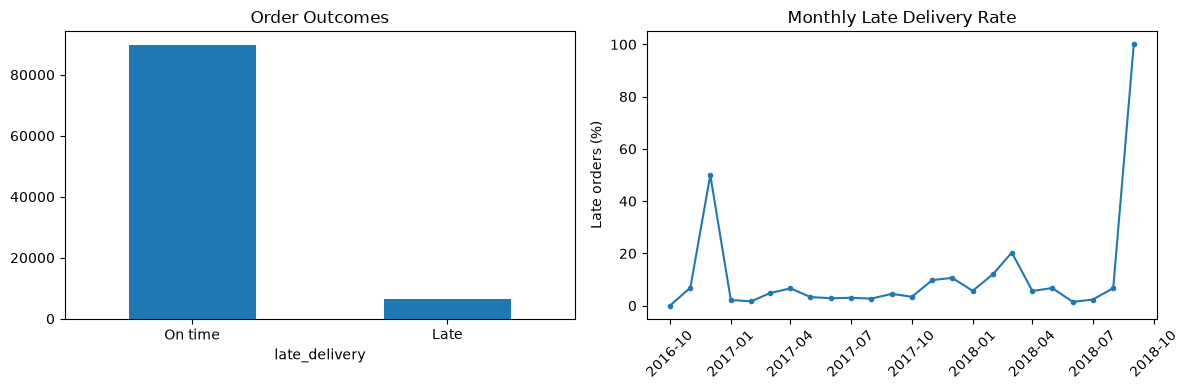

,orders,late_rate
month,,
2016-10-01,232,0.000
2016-11-01,29,0.069
2016-12-01,2,0.500
2017-01-01,601,0.022
2017-02-01,1495,0.017
2017-03-01,2666,0.048
2017-04-01,2098,0.066
2017-05-01,3654,0.033
2017-06-01,3207,0.028


In [7]:
monthly = (
    orders.assign(month=orders["carrier_at"].dt.to_period("M").dt.to_timestamp())
    .groupby("month").agg(orders=("late_delivery", "size"), late_rate=("late_delivery", "mean"))
)



fig, axs = plt.subplots(1, 2, figsize=(12, 4))
orders["late_delivery"].value_counts().sort_index().rename(index={0: "On time", 1: "Late"}).plot.bar(ax=axs[0])
axs[0].set_title("Order Outcomes")
axs[0].tick_params(axis='x', rotation=0)
axs[1].plot(monthly.index, monthly["late_rate"] * 100, marker=".")
axs[1].set_title("Monthly Late Delivery Rate") 
axs[1].set_ylabel("Late orders (%)") 
axs[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
display(monthly.tail(200))

**Order Outcomes**: Most orders were delivered on time, while only a small percentage were late. This shows that the dataset is imbalanced, so accuracy alone may not be a good way to evaluate the model.

**Monthly Late Delivery Rate**: The late-delivery rate changes across months, with some noticeable spikes. The unusually high rates at the beginning and end may be caused by months with very few orders and should be checked.

**Conclusion**: Because the data is imbalanced and delivery patterns change over time, Use a time-based split and focus on metrics such as Recall@15% and Precision@15%.

## Seller Delivery History

Use seller's past delivery performance to help predict late deliveries.
- Use only orders that were completed before the current prediction time.
- Use `merge_asof` to match each order with the seller's previous delivery history.
- Avoid **Data Leakage** by not using current or future delivery results.
- If a seller has no delivery history, use the average late-delivery rate from the training data instead.

In [8]:
def add_past_seller_history(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()
    seller_key = result["main_seller_id"].fillna("unknown").astype(str)
    
    events = pd.DataFrame({
        "main_seller_id": seller_key,
        "delivered_at": result["delivered_at"], 
        "late_delivery": result["late_delivery"].astype(int), 
    }).sort_values("delivered_at").reset_index(drop=True) 
    events["seller_past_n"] = events.groupby("main_seller_id").cumcount() + 1 
    events["seller_past_late"] = events.groupby("main_seller_id")["late_delivery"].cumsum() 

    left = pd.DataFrame({
        "order_id": result["order_id"],
        "main_seller_id": seller_key,
        "carrier_at": result["carrier_at"],
    }).sort_values("carrier_at")
    
    
    matched = pd.merge_asof(
        left, events[["main_seller_id", "delivered_at", "seller_past_n", "seller_past_late"]],
        by="main_seller_id", left_on="carrier_at", right_on="delivered_at",
        direction="backward", allow_exact_matches=False,
    )
    
    
    
    
    
    matched = matched.rename(columns={"delivered_at": "seller_last_completed_at"})
    check = matched["seller_last_completed_at"].notna()
    assert (matched.loc[check, "seller_last_completed_at"] < matched.loc[check, "carrier_at"]).all()
    
    result = result.merge(
        matched[["order_id", "seller_past_n", "seller_past_late", "seller_last_completed_at"]],
        on="order_id", how="left", validate="one_to_one",
    )
    result["seller_past_n"] = result["seller_past_n"].fillna(0).astype(int)
    result["seller_past_late"] = result["seller_past_late"].fillna(0).astype(int)
    return result

orders = add_past_seller_history(orders)
print("Orders with at least one completed historical delivery from this seller:",
      f"{(orders['seller_past_n'] > 0).mean():.1%}")

Orders with at least one completed historical delivery from this seller: 95.3%


## Chronological Train / Validation / Test

We split the data by time instead of randomly to avoid Data Leakage and simulate real-world predictions.

- **Train:** Use past orders that were already delivered before validation starts to train the model.
- **Validation:** Use later orders that were delivered before the test period starts to compare and select the best model.
- **Test:** Use the newest orders to evaluate the final model.

This ensures the model only learns from information that was available at that time. We use validation to select the best model and test only once for the final evaluation.

In [9]:
orders = orders.sort_values(["carrier_at", "order_id"]).reset_index(drop=True)
carrier_dates = orders["carrier_at"].dt.normalize()
val_start = carrier_dates.iloc[int(len(orders) * 0.70)]
test_start = carrier_dates.iloc[int(len(orders) * 0.85)]
if not val_start < test_start:
    raise ValueError("Temporal split boundaries overlap")

train_mask = (carrier_dates < val_start) & (orders["delivered_at"] < val_start)
valid_mask = ((carrier_dates >= val_start) & (carrier_dates < test_start) &
              (orders["delivered_at"] < test_start))
test_mask = (carrier_dates >= test_start)

assert (train_mask & valid_mask).sum() == 0
assert (train_mask & test_mask).sum() == 0
assert (valid_mask & test_mask).sum() == 0
for label, mask in [("Train", train_mask), ("Validation", valid_mask), ("Test", test_mask)]:
    if int(mask.sum()) < 100 or orders.loc[mask, "late_delivery"].nunique() != 2:
        raise ValueError(f"Insufficient rows / label classes in {label}; adjust the date boundaries")

split_summary = pd.DataFrame([
    {"split": label, "orders": int(mask.sum()),
     "late_rate": orders.loc[mask, "late_delivery"].mean(),
     "first_handoff": orders.loc[mask, "carrier_at"].min().date(),
     "last_handoff": orders.loc[mask, "carrier_at"].max().date()}
    for label, mask in [("Train", train_mask), ("Validation", valid_mask), ("Test", test_mask)]
])
print("Validation begins", val_start.date(), "| Test begins", test_start.date())
print("Observations omitted due to label availability:",
      len(orders) - int(train_mask.sum() + valid_mask.sum() + test_mask.sum()))
display(split_summary)

Validation begins 2018-04-17 | Test begins 2018-06-22
Observations omitted due to label availability: 3694


,split,orders,late_rate,first_handoff,last_handoff
0,Train,64741,0.069,2016-10-08,2018-04-16
1,Validation,13236,0.044,2018-04-17,2018-06-20
2,Test,14610,0.043,2018-06-22,2018-09-11


## Feature Engineering

Two feature sets are compared using the same orders to see if additional information improves late-delivery prediction.

- **Purchase-time features:** Information available when an order is placed, such as price, shipping cost, item count, product category, location, purchase date, and estimated delivery time.

- **Handoff-time features:** All purchase-time features, plus information available when the seller hands the package to the carrier, such as preparation time, remaining delivery time, shipping delays, estimated distance, payment details, and seller's past delivery history.

Handoff-time prediction may be easier because more information is available. For example, the promised delivery date may have already passed.

To avoid **Data Leakage**, actual delivery dates, actual delivery duration, raw seller IDs, and the target variable (`late_delivery`) are not used as model features.

In [10]:
BASE_NUMERIC = [
    "estimated_lead_days", "order_gmv", "freight_total", "freight_share",
    "item_count", "distinct_sellers", "distinct_categories", "avg_product_weight_g",
    "avg_product_volume_cm3", "same_state", "purchase_hour",
]
BASE_CATEGORICAL = ["customer_state", "main_seller_state", "main_category",
                    "purchase_month", "purchase_weekday"]
NEW_NUMERIC = [
    "days_purchase_to_carrier", "days_approval_to_carrier",
    "days_remaining_at_handoff", "days_after_ship_deadline",
    "handoff_after_promise", "handoff_after_ship_deadline",
    "route_distance_km", "freight_per_item", "max_product_weight_g",
    "payment_total", "max_installments", "seller_prior_order_count",
    "seller_prior_late_rate",
]
NEW_CATEGORICAL = ["handoff_weekday", "handoff_month", "main_payment_type"]
BASE_FEATURES = BASE_NUMERIC + BASE_CATEGORICAL
ADV_NUMERIC = BASE_NUMERIC + NEW_NUMERIC
ADV_CATEGORICAL = BASE_CATEGORICAL + NEW_CATEGORICAL
ADV_FEATURES = ADV_NUMERIC + ADV_CATEGORICAL

FORBIDDEN = {"order_id", "main_seller_id", "delivered_at", "late_delivery",
             "delivery_days", "is_on_time", "review_score", "avg_review_score",
             "order_status", "seller_last_completed_at"}
assert not (set(ADV_FEATURES) & FORBIDDEN)

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance between ZIP prefix centers (not a driving distance)."""
    lat1, lon1, lat2, lon2 = (pd.to_numeric(x, errors="coerce")
                             for x in (lat1, lon1, lat2, lon2))
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlon / 2)**2
    distance = 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    valid = (lat1.between(-90, 90) & lat2.between(-90, 90) &
             lon1.between(-180, 180) & lon2.between(-180, 180))
    return distance.where(valid & distance.between(0, 4500))

# Learned from *training labels only*, never from validation or test.
TRAIN_PRIOR = float(orders.loc[train_mask, "late_delivery"].mean())

def make_features(frame: pd.DataFrame, *, training_prior: float = TRAIN_PRIOR) -> pd.DataFrame:
    df = frame.copy()
    for col in DATE_COLS:
        if col in df:
            df[col] = pd.to_datetime(df[col], errors="coerce")
    df["estimated_lead_days"] = (df["estimated_delivery_at"] - df["purchased_at"]).dt.total_seconds() / 86400
    df["freight_share"] = df["freight_total"] / (df["order_gmv"].abs() + 1)
    df["same_state"] = (df["customer_state"] == df["main_seller_state"]).where(
        df["customer_state"].notna() & df["main_seller_state"].notna()).astype(float)
    df["purchase_hour"] = df["purchased_at"].dt.hour
    df["purchase_month"] = df["purchased_at"].dt.month.astype("string")
    df["purchase_weekday"] = df["purchased_at"].dt.dayofweek.astype("string")

    df["days_purchase_to_carrier"] = (df["carrier_at"] - df["purchased_at"]).dt.total_seconds() / 86400
    df["days_approval_to_carrier"] = (df["carrier_at"] - df["approved_at"]).dt.total_seconds() / 86400
    df["days_remaining_at_handoff"] = (df["estimated_delivery_at"] - df["carrier_at"]).dt.total_seconds() / 86400
    df["days_after_ship_deadline"] = (df["carrier_at"] - df["last_ship_deadline_at"]).dt.total_seconds() / 86400
    df["handoff_after_promise"] = (df["carrier_at"].dt.normalize() > df["estimated_delivery_at"].dt.normalize()).astype(float)
    df["handoff_after_ship_deadline"] = (df["carrier_at"] > df["last_ship_deadline_at"]).astype(float)
    df.loc[df["last_ship_deadline_at"].isna(), "handoff_after_ship_deadline"] = np.nan
    df["route_distance_km"] = haversine_km(df["customer_lat"], df["customer_lng"],
                                             df["seller_lat"], df["seller_lng"])
    df["freight_per_item"] = df["freight_total"] / df["item_count"].replace(0, np.nan)
    past_n = df["seller_past_n"].fillna(0)
    past_late = df["seller_past_late"].fillna(0)
    df["seller_prior_order_count"] = np.log1p(past_n)
    df["seller_prior_late_rate"] = (past_late + 20 * training_prior) / (past_n + 20)
    df["handoff_weekday"] = df["carrier_at"].dt.dayofweek.astype("string")
    df["handoff_month"] = df["carrier_at"].dt.month.astype("string")

    result = df[ADV_FEATURES].copy()
    for feature in ADV_NUMERIC:
        result[feature] = pd.to_numeric(result[feature], errors="coerce").replace([np.inf, -np.inf], np.nan)
    for feature in ADV_CATEGORICAL:
        result[feature] = result[feature].fillna("unknown").replace("", "unknown").astype(str)
    return result

X = make_features(orders)
y = orders["late_delivery"].astype(int)
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_valid, y_valid = X.loc[valid_mask], y.loc[valid_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]
assert set(X.columns) == set(ADV_FEATURES)
print("Features: baseline", len(BASE_FEATURES), "| enhanced", len(ADV_FEATURES))
display(X_train.head(3))

Features: baseline 16 | enhanced 32


,estimated_lead_days,order_gmv,freight_total,freight_share,item_count,distinct_sellers,distinct_categories,avg_product_weight_g,avg_product_volume_cm3,same_state,purchase_hour,days_purchase_to_carrier,days_approval_to_carrier,days_remaining_at_handoff,days_after_ship_deadline,handoff_after_promise,handoff_after_ship_deadline,route_distance_km,freight_per_item,max_product_weight_g,payment_total,max_installments,seller_prior_order_count,seller_prior_late_rate,customer_state,main_seller_state,main_category,purchase_month,purchase_weekday,handoff_weekday,handoff_month,main_payment_type
0,50.061,29.990,10.960,0.354,1,1,1,"9,000.000","2,640.000",1.000,22,4.502,4.010,45.560,0.000,0.000,0.000,194.576,10.960,"9,000.000",40.950,4.000,0.000,0.069,SP,SP,fashion_shoes,10,0,5,10,credit_card
1,62.450,47.800,53.640,1.099,2,1,1,"1,500.000","14,625.000",0.000,13,4.024,4.000,58.426,0.000,0.000,0.000,"1,043.479",26.820,"1,500.000",101.440,10.000,0.000,0.069,MT,SP,furniture_decor,10,1,5,10,credit_card
2,56.407,93.900,17.610,0.186,1,1,1,"1,200.000","12,500.000",0.000,14,4.023,4.000,52.384,0.000,0.000,0.000,988.066,17.610,"1,200.000",111.510,4.000,0.000,0.069,RJ,PR,furniture_decor,10,1,5,10,credit_card


## Operational Metric: Top 15% Review Capacity

In real-world situations, companies may not have enough staff, time, or budget to review every order.

The model predicts the risk of late delivery for all orders and selects the **top 15% with the highest risk** for review.

The model is evaluated using:

- **Recall@15%:** How many of the actual late deliveries are found in the top 15%.
- **Precision@15%:** How many of the selected orders are actually late.
- **Lift@15%:** How much better the selected group is at finding late deliveries compared to random selection.
- **Average Precision (PR-AUC):** How well the model ranks risky orders overall.

The 15% limit is an assumed review capacity for this project. It does not mean that 15% of all orders are late. The goal is to help prioritize high-risk orders while using limited resources efficiently.

In [11]:
def top_fraction_flag(probabilities, fraction=REVIEW_CAPACITY):
    probabilities = np.asarray(probabilities, dtype=float)
    count = max(1, int(np.ceil(len(probabilities) * fraction)))
    flag = np.zeros(len(probabilities), dtype=int)
    flag[np.argsort(-probabilities, kind="stable")[:count]] = 1
    return flag

def queue_metrics(actual, probabilities, fraction=REVIEW_CAPACITY):
    y_true = np.asarray(actual, dtype=int)
    selected = top_fraction_flag(probabilities, fraction)
    caught = int(np.sum((y_true == 1) & (selected == 1)))
    flagged = int(np.sum(selected))
    all_late = int(np.sum(y_true))
    base = float(np.mean(y_true))
    precision = caught / flagged if flagged else 0
    recall = caught / all_late if all_late else 0
    return {"flagged": flagged, "late_caught": caught,
            "precision@15%": precision, "recall@15%": recall,
            "lift@15%": precision / base if base else np.nan}

def score_model(actual, probabilities):
    return {"PR-AUC": average_precision_score(actual, probabilities),
            "ROC-AUC": roc_auc_score(actual, probabilities),
            "Brier": brier_score_loss(actual, probabilities),
            **queue_metrics(actual, probabilities)}

# Sanity checks: random-like ranking catches ~15% of the late cases in expectation.
assert top_fraction_flag([0.1, 0.9, 0.2, 0.5], 0.25).tolist() == [0, 1, 0, 0]

## Models and Validation-Based Selection

1. **Purchase-time Logistic Regression:** A basic model using only purchase-time features for comparison.
2. **Handoff-time Logistic Regression:** A simple model using additional information available at handoff.
3. **Handoff-time Random Forest:** A model that can learn more complex patterns in the data.
4. **CatBoost (depth 4 and 6):** A model designed for table data that can handle both numeric and categorical features without one-hot encoding.

The best model is selected using **Recall\@15% on the validation set**, which measures how many actual late deliveries are found in the top 15% highest-risk orders.

If models have the same Recall\@15%, **PR-AUC** is used to decide.

CatBoost uses validation data to stop training when performance stops improving (**early stopping**). The test set is kept separate for final evaluation.


In [12]:
def make_sklearn_preprocessor(nums, cats):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=40)),
    ])
    return ColumnTransformer([("numeric", numeric, nums), ("categorical", categorical, cats)])

def logistic_model(nums, cats):
    return Pipeline([
        ("preprocess", make_sklearn_preprocessor(nums, cats)),
        ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE)),
    ])

baseline_model = logistic_model(BASE_NUMERIC, BASE_CATEGORICAL)
baseline_model.fit(X_train[BASE_FEATURES], y_train)
baseline_valid_p = baseline_model.predict_proba(X_valid[BASE_FEATURES])[:, 1]
validation_rows = [{"model": "Purchase-time logistic baseline", "checkpoint": "purchase",
                    **score_model(y_valid, baseline_valid_p)}]
trained = {"Purchase-time logistic baseline": baseline_model}

lr = logistic_model(ADV_NUMERIC, ADV_CATEGORICAL)
print("Training handoff logistic ...")
lr.fit(X_train[ADV_FEATURES], y_train)
trained["Handoff logistic"] = lr
validation_rows.append({"model": "Handoff logistic", "checkpoint": "handoff",
                        **score_model(y_valid, lr.predict_proba(X_valid[ADV_FEATURES])[:, 1])})

rf = Pipeline([
    ("preprocess", make_sklearn_preprocessor(ADV_NUMERIC, ADV_CATEGORICAL)),
    ("model", RandomForestClassifier(n_estimators=180, min_samples_leaf=15,
                                      max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE)),
])
print("Training handoff random forest ...")
rf.fit(X_train[ADV_FEATURES], y_train)
trained["Handoff random forest"] = rf
validation_rows.append({"model": "Handoff random forest", "checkpoint": "handoff",
                        **score_model(y_valid, rf.predict_proba(X_valid[ADV_FEATURES])[:, 1])})

for depth in (4, 6):
    name = f"Handoff CatBoost depth={depth}"
    print("Training", name, "...")
    cb = CatBoostClassifier(
        iterations=650, depth=depth, learning_rate=0.045, l2_leaf_reg=5,
        loss_function="Logloss", eval_metric="PRAUC", random_seed=RANDOM_STATE,
        thread_count=4, verbose=False, allow_writing_files=False,
    )
    cb.fit(X_train[ADV_FEATURES], y_train, cat_features=ADV_CATEGORICAL,
           eval_set=(X_valid[ADV_FEATURES], y_valid), early_stopping_rounds=75,
           verbose=False)
    trained[name] = cb
    validation_rows.append({"model": name, "checkpoint": "handoff",
                            **score_model(y_valid, cb.predict_proba(X_valid[ADV_FEATURES])[:, 1])})

validation_results = (pd.DataFrame(validation_rows)
                      .sort_values(["recall@15%", "PR-AUC"], ascending=False))
display(validation_results[["model", "checkpoint", "PR-AUC", "ROC-AUC", "precision@15%",
                            "recall@15%", "lift@15%", "late_caught", "flagged"]])

Training handoff logistic ...
Training handoff random forest ...
Training Handoff CatBoost depth=4 ...
Training Handoff CatBoost depth=6 ...


,model,checkpoint,PR-AUC,ROC-AUC,precision@15%,recall@15%,lift@15%,late_caught,flagged
4,Handoff CatBoost depth=6,handoff,0.335,0.857,0.183,0.617,4.114,363,1986
3,Handoff CatBoost depth=4,handoff,0.342,0.862,0.182,0.616,4.103,362,1986
1,Handoff logistic,handoff,0.299,0.842,0.175,0.592,3.944,348,1986
2,Handoff random forest,handoff,0.289,0.804,0.156,0.526,3.502,309,1986
0,Purchase-time logistic baseline,purchase,0.120,0.753,0.125,0.422,2.811,248,1986


In [13]:
# Handoff models are compared against the purchase-time baseline on the same rows.
# Do not use test scores to pick a model.
handoff_valid = validation_results.query("checkpoint == 'handoff'")
best_name = str(handoff_valid.iloc[0]["model"])
best_model = trained[best_name]
print("Chosen handoff model on validation:", best_name)
print("Validation late rate:", f"{y_valid.mean():.2%}")
print("Validation recall@15%:", f"{handoff_valid.iloc[0]['recall@15%']:.1%}")

Chosen handoff model on validation: Handoff CatBoost depth=6
Validation late rate: 4.44%
Validation recall@15%: 61.7%


## Final Model Evaluation on Test Data

The baseline and improved models are tested using **the same test orders** to make a fair comparison.

The test data is used only once, after the best model has been selected.

Model performance is compared using **Recall@15%, Precision@15%, and PR-AUC** instead of accuracy.

The handoff-time model uses information available when the seller hands the package to the carrier, not when the customer places the order.


Test handoff period begins: 2018-06-22
Test prevalence: 4.28%


,model,PR-AUC,ROC-AUC,precision@15%,recall@15%,lift@15%,late_caught,flagged
0,Purchase-time baseline,0.082,0.679,0.072,0.251,1.674,157,2192
1,Handoff CatBoost depth=6,0.515,0.876,0.204,0.715,4.767,447,2192


Recall@15% absolute change: +46.4%

Best handoff model: top-15% queue confusion report
              precision    recall  f1-score   support

     On time       0.99      0.88      0.93     13985
        Late       0.20      0.72      0.32       625

    accuracy                           0.87     14610
   macro avg       0.59      0.80      0.62     14610
weighted avg       0.95      0.87      0.90     14610



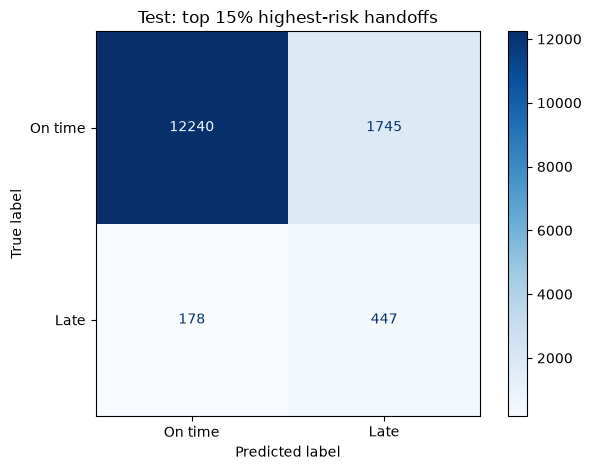

In [14]:
baseline_test_p = baseline_model.predict_proba(X_test[BASE_FEATURES])[:, 1]
best_test_p = best_model.predict_proba(X_test[ADV_FEATURES])[:, 1]

baseline_scores = score_model(y_test, baseline_test_p)
best_scores = score_model(y_test, best_test_p)
results = pd.DataFrame([
    {"model": "Purchase-time baseline", "checkpoint": "purchase", **baseline_scores},
    {"model": best_name, "checkpoint": "handoff", **best_scores},
])
print("Test handoff period begins:", test_start.date())
print("Test prevalence:", f"{y_test.mean():.2%}")
display(results[["model", "PR-AUC", "ROC-AUC", "precision@15%",
                 "recall@15%", "lift@15%", "late_caught", "flagged"]])
print("Recall@15% absolute change:", f"{best_scores['recall@15%'] - baseline_scores['recall@15%']:+.1%}")

flagged = top_fraction_flag(best_test_p)
print("\nBest handoff model: top-15% queue confusion report")
print(classification_report(y_test, flagged, target_names=["On time", "Late"], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, flagged),
                       display_labels=["On time", "Late"]).plot(cmap="Blues", values_format="d")
plt.title("Test: top 15% highest-risk handoffs")
plt.tight_layout(); plt.show()

The models were tested on **14,610 orders**, starting from June 22, 2018. Only **4.28% of orders were actually late**.

### Model Comparison

The **Handoff CatBoost (depth=6)** model performed much better than the Purchase-time baseline.

- **Recall@15%:** Increased from 25.1% to 71.5%, meaning the improved model found more late deliveries.
- **Precision@15%:** Increased from 7.2% to 20.4%, meaning more selected orders were actually late.
- **Lift@15%:** Increased from 1.67 to 4.77, meaning the improved model was about 4.77 times better than random selection at finding late deliveries.
- **PR-AUC:** Increased from 0.082 to 0.515, showing better overall performance in ranking late deliveries.

### Confusion Matrix

The best model selected **2,192 orders (top 15%)** for review.

- **447 orders:** Correctly identified as late.
- **1,745 orders:** Selected as high-risk but actually delivered on time.
- **178 orders:** Actually late but not selected.
- **12,240 orders:** Correctly identified as on time.

### Conclusion

The Handoff CatBoost model performed better than the Purchase-time baseline. It found **447 out of 625 late deliveries (71.5%)** by reviewing only 15% of all orders.

This shows that information available at handoff helps the model identify high-risk deliveries more effectively. However, many selected orders were still delivered on time.

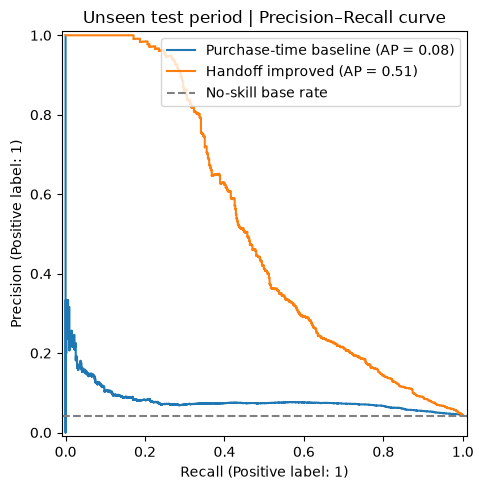

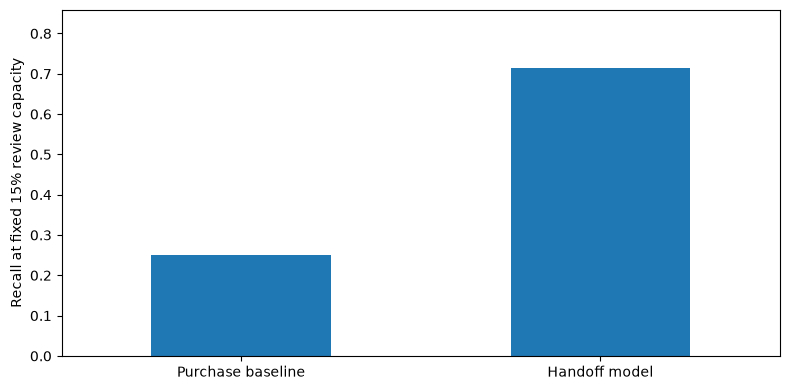

In [15]:
plt.figure(figsize=(8, 5))
PrecisionRecallDisplay.from_predictions(y_test, baseline_test_p, name="Purchase-time baseline", ax=plt.gca())
PrecisionRecallDisplay.from_predictions(y_test, best_test_p, name="Handoff improved", ax=plt.gca())
plt.axhline(y_test.mean(), linestyle="--", color="gray", label="No-skill base rate")
plt.title("Unseen test period | Precision–Recall curve")
plt.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
chart = pd.DataFrame({
    "Purchase baseline": [baseline_scores["recall@15%"]],
    "Handoff model": [best_scores["recall@15%"]],
}, index=["Recall@15%"])
chart.T.plot.bar(ax=ax, legend=False)
ax.set_ylabel("Recall at fixed 15% review capacity")
ax.set_ylim(0, max(chart.to_numpy().max() * 1.2, 0.2))
ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

### Precision–Recall Curve
- **Blue line (Purchase-time baseline):** Shows lower performance, with an Average Precision (AP) of 0.08.
- **Orange line (Handoff model):** Shows much better performance, with an AP of 0.51.
- **Gray dashed line:** Shows the performance of random predictions.
The orange line stays higher than the blue line, meaning the Handoff model is better at identifying late deliveries.

### Recall at 15% Review Capacity
The second graph shows how many actual late deliveries each model can find when only the top 15% highest-risk orders are selected.
- **Purchase-time baseline:** Finds about 25% of all late deliveries.
- **Handoff model:** Finds about 71.5% of all late deliveries.

### Conclusion
The **Handoff model performs much better** than the Purchase-time baseline in both graphs.
With the same 15% review limit, the Handoff model can identify more late deliveries. This shows that using information available when the seller hands the package to the carrier helps improve prediction performance.